# PCI and M&R Quantities from a Field-Survey Spreadsheet (Homework 3 & 4 procedure)

This notebook reads the asphalt-road distress survey sheet (e.g. branch ITA3) from Excel and follows the
procedure of Homework 3 (PCI) and Homework 4 (M&R quantities):

1. **PCI** of each sample unit, section and branch, following the asphalt-road procedure in
   Shahin, M. Y. (2005), *Pavement Management for Airports, Roads, and Parking Lots*, Springer
   — §3.5.1 (Steps 1–4), Eq. 3-3 for the allowable number of deducts, Eq. 3-4 for the section PCI,
   the Appendix B deduct-value curves (Figs. B-20 to B-44, metric versions where the book gives one),
   and the corrected-deduct-value curves of Fig. B-45 (Roads and Parking Lots: Asphalt).
2. **M&R selection** from the decision-tree matrix (Table 7, Dammam Municipality).
3. **M&R type** from the Survey sheet (Homework 4 table), and the **estimated section quantity** =
   (total area of each distress in the section / area of samples inspected) × section area, with the section area
   from the Areas sheet.
4. **Cost** = unit cost × that quantity, with the unit costs read from a separate Excel file
   (Maintenance No. | Maintenance Type | Unit Cost (SAR)).

**About the curves.** The deduct curves and the CDV curves were digitized from the scanned book
figures. Expect read-off differences of roughly ±1–2 deduct points versus reading the charts by hand;
a value read by hand can be entered in `DV_OVERRIDES` (section 3).

**To run:** run all cells. Section 3.3 asks for the survey Excel file (upload in Colab, file dialog or
typed path in Jupyter), then for the maintenance unit-cost Excel file. Section areas are read from the
`Areas` sheet of the survey workbook.

Deduct values are rounded to the nearest 0.5 (`DV_ROUND`), as when read from the graphs.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', 300)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

## 1. Reference data (Shahin 2005, Appendix B)

### 1.1 Distress types and units (ASTM D6433 / Shahin numbering)
Density = quantity / sample-unit area × 100. Quantities are m² for area distresses, linear m for
4, 7, 8, 9, 10, and number of potholes for 13.

In [ ]:
DISTRESS = {
    1: ('Alligator cracking', 'm2'),          2: ('Bleeding', 'm2'),
    3: ('Block cracking', 'm2'),              4: ('Bumps and sags', 'm'),
    5: ('Corrugation', 'm2'),                 6: ('Depression', 'm2'),
    7: ('Edge cracking', 'm'),                8: ('Joint reflection cracking', 'm'),
    9: ('Lane/shoulder drop-off', 'm'),       10: ('Longitudinal & transverse cracking', 'm'),
    11: ('Patching & utility cut patching', 'm2'), 12: ('Polished aggregate', 'm2'),
    13: ('Potholes', 'no.'),                  14: ('Railroad crossing', 'm2'),
    15: ('Rutting', 'm2'),                    16: ('Shoving', 'm2'),
    17: ('Slippage cracking', 'm2'),          18: ('Swell', 'm2'),
    19: ('Weathering & raveling', 'm2'),
}

### 1.2 Deduct-value curves (Figs. B-20 … B-44)
Each curve is stored as `(density %, deduct value)` points and interpolated linearly in log10(density),
which is how the curves are plotted. Polished aggregate (12) has a single curve, severity `'N'`.
Some book curves stop before 100 % (e.g. bumps, patching, swell, edge cracking); beyond the last
point the curve is extended along its final slope and capped at 100.

In [ ]:
DV_CURVES = {
    # 1: Alligator cracking
    1: {
        'H': ([0.103, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.452],
              [12.6, 14.4, 16.0, 18.3, 22.4, 26.0, 30.7, 36.2, 40.2, 46.3, 53.5, 57.9, 62.2, 67.3, 71.0, 76.0, 82.5, 87.0, 91.1]),
        'M': ([0.103, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.452],
              [6.9, 8.7, 10.4, 12.5, 16.0, 18.5, 21.6, 25.5, 28.3, 32.8, 38.4, 42.4, 47.0, 52.2, 56.0, 61.2, 68.1, 72.6, 77.5]),
        'L': ([0.103, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.452],
              [4.2, 4.2, 4.4, 4.8, 6.3, 8.0, 10.7, 14.4, 16.9, 21.0, 26.0, 29.6, 33.2, 37.9, 41.3, 46.1, 52.5, 57.2, 61.5]),
    },
    # 2: Bleeding
    2: {
        'H': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.614],
              [2.0, 2.3, 2.5, 2.9, 3.5, 4.2, 5.4, 7.0, 8.3, 10.8, 14.7, 18.2, 23.1, 29.7, 35.0, 43.0, 54.9, 63.4, 72.4]),
        'M': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.614],
              [0.7, 0.8, 0.9, 1.2, 1.8, 2.1, 2.7, 3.7, 4.6, 6.4, 8.8, 10.6, 13.0, 16.3, 18.8, 22.7, 29.2, 34.2, 39.6]),
        'L': ([1.844, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 96.831],
              [0.7, 0.7, 0.8, 1.3, 1.9, 2.9, 4.8, 6.2, 8.6, 12.7, 16.2, 19.6]),
    },
    # 3: Block cracking
    3: {
        'H': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.611],
              [0.5, 1.0, 1.5, 2.3, 3.7, 4.9, 6.9, 9.8, 12.3, 15.8, 20.8, 24.7, 30.0, 36.6, 41.9, 49.3, 59.0, 65.5, 71.5]),
        'M': ([0.548, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.611],
              [0.5, 1.2, 2.6, 4.5, 6.0, 8.4, 11.4, 13.6, 16.5, 20.5, 23.2, 27.6, 34.1, 38.7, 43.3]),
        'L': ([0.548, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.611],
              [0.5, 0.5, 0.5, 1.1, 1.9, 3.2, 5.0, 6.3, 8.4, 11.0, 13.1, 16.2, 20.4, 24.2, 27.9]),
    },
    # 4: Bumps and sags
    4: {
        'H': ([0.337, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 32.136],
              [20.4, 25.4, 29.7, 34.3, 39.5, 43.8, 50.1, 59.3, 65.5, 72.3, 81.0, 88.1, 98.0, 99.5]),
        'M': ([0.332, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 32.658],
              [5.0, 7.7, 10.1, 12.4, 15.4, 17.8, 21.7, 28.6, 33.9, 40.9, 50.7, 59.7, 75.8, 79.2]),
        'L': ([0.357, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 32.396],
              [0.4, 1.2, 2.1, 3.1, 4.4, 5.3, 7.0, 10.2, 12.7, 17.1, 23.5, 29.0, 37.8, 39.5]),
    },
    # 5: Corrugation
    5: {
        'H': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.614],
              [10.6, 14.9, 18.3, 22.9, 28.1, 31.2, 34.3, 38.2, 41.1, 45.3, 51.6, 56.3, 61.7, 67.8, 72.0, 77.9, 85.0, 89.4, 93.9]),
        'M': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.614],
              [5.3, 5.9, 6.7, 8.0, 10.5, 12.4, 15.4, 19.3, 22.0, 25.6, 31.3, 35.3, 40.0, 45.3, 49.1, 54.4, 62.2, 68.0, 73.8]),
        'L': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.614],
              [1.1, 1.1, 1.1, 1.1, 1.2, 1.4, 2.3, 3.3, 4.0, 5.3, 7.7, 9.9, 12.9, 16.9, 19.8, 24.2, 30.3, 34.6, 38.8]),
    },
    # 6: Depression
    6: {
        'H': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.608],
              [12.0, 12.6, 13.1, 13.9, 15.0, 15.8, 16.8, 18.6, 20.4, 24.2, 30.5, 36.5, 43.6, 51.3, 56.4, 62.7, 68.5, 71.6, 74.3]),
        'M': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 95.273],
              [8.0, 8.0, 8.0, 8.0, 8.0, 8.0, 8.6, 9.7, 11.1, 13.6, 18.2, 22.8, 29.7, 37.6, 43.0, 49.5, 55.4, 57.9, 59.5]),
        'L': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.608],
              [3.9, 3.9, 3.9, 3.9, 3.9, 4.1, 4.1, 4.5, 5.1, 6.6, 9.9, 12.6, 17.4, 24.4, 29.3, 35.7, 41.8, 44.9, 48.0]),
    },
    # 7: Edge cracking
    7: {
        'H': ([0.338, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 78.52],
              [8.1, 8.4, 8.7, 9.2, 9.8, 10.7, 12.2, 15.9, 19.4, 24.3, 30.1, 34.0, 38.8, 44.2, 46.9, 47.1]),
        'M': ([0.341, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 78.52],
              [4.1, 4.5, 5.1, 5.7, 6.6, 7.1, 8.3, 10.5, 12.1, 14.5, 17.8, 20.1, 23.1, 26.5, 26.8, 27.8]),
        'L': ([0.366, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 77.265],
              [0.5, 1.0, 1.6, 2.0, 2.3, 2.5, 3.1, 4.0, 4.2, 5.1, 6.9, 8.3, 10.7, 14.0, 14.2, 14.3]),
    },
    # 8: Joint reflection cracking
    8: {
        'H': ([0.32, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.608],
              [2.0, 4.1, 5.5, 7.2, 9.6, 11.6, 14.7, 19.9, 24.5, 31.6, 41.5, 48.9, 58.6, 67.9, 71.5, 73.2]),
        'M': ([0.32, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.608],
              [0.5, 1.0, 1.8, 2.6, 3.9, 5.1, 6.9, 9.9, 12.5, 16.4, 22.0, 26.1, 32.1, 38.3, 41.2, 43.2]),
        'L': ([1.658, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.608],
              [0.5, 0.9, 2.3, 3.8, 4.7, 6.3, 8.5, 10.4, 13.3, 18.2, 21.3, 25.5]),
    },
    # 9: Lane/shoulder drop-off
    9: {
        'H': ([1.58, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 58.394],
              [6.0, 6.3, 6.9, 8.8, 11.2, 14.6, 19.5, 23.9, 31.5, 43.8, 46.3]),
        'M': ([1.568, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 61.19],
              [4.0, 4.0, 4.3, 5.3, 6.5, 8.2, 10.6, 13.1, 18.2, 24.6, 26.3]),
        'L': ([1.568, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 58.394],
              [2.0, 2.0, 2.1, 2.7, 3.5, 4.6, 6.5, 8.3, 11.4, 14.6, 14.6]),
    },
    # 10: Longitudinal & transverse cracking
    10: {
        'H': ([0.326, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.616],
              [3.9, 4.9, 6.5, 8.4, 11.4, 13.8, 17.7, 23.2, 27.7, 33.9, 42.6, 49.2, 59.8, 73.0, 80.0, 85.8]),
        'M': ([0.537, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.616],
              [0.5, 1.3, 2.4, 4.1, 5.5, 8.2, 11.8, 14.6, 18.3, 22.7, 25.9, 30.6, 36.3, 40.1, 43.8]),
        'L': ([1.883, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.616],
              [0.5, 0.6, 1.7, 3.6, 5.7, 8.0, 10.8, 12.8, 16.0, 20.6, 24.3, 27.9]),
    },
    # 11: Patching & utility cut patching
    11: {
        'H': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 48.329],
              [6.3, 7.5, 8.6, 10.9, 14.8, 17.1, 19.5, 22.9, 25.4, 30.0, 37.8, 44.2, 51.6, 60.9, 67.2, 74.1, 79.5]),
        'M': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 48.713],
              [2.8, 3.6, 4.2, 5.1, 7.0, 8.3, 9.7, 12.2, 14.2, 17.5, 22.6, 26.7, 31.3, 37.0, 41.5, 48.3, 57.6]),
        'L': ([0.377, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 57.508],
              [0.7, 1.1, 1.7, 2.5, 3.7, 4.8, 6.7, 10.5, 13.1, 16.3, 20.4, 23.1, 27.4, 33.9, 34.4]),
    },
    # 12: Polished aggregate
    12: {
        'N': ([2.786, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.651],
              [0.5, 0.5, 1.0, 2.1, 3.1, 4.9, 6.1, 8.1, 12.2, 16.0, 19.5]),
    },
    # 13: Potholes
    13: {
        'H': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 7.74],
              [20.7, 22.3, 25.5, 31.6, 39.9, 45.6, 52.6, 60.7, 66.9, 76.2, 88.6, 97.0, 97.6]),
        'M': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 15.666],
              [5.4, 8.1, 10.3, 14.4, 20.9, 25.6, 31.6, 39.1, 45.3, 54.9, 68.6, 77.7, 87.4, 98.7, 99.6]),
        'L': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.651],
              [2.5, 3.7, 5.1, 7.7, 11.9, 15.4, 20.0, 25.4, 29.6, 36.0, 44.4, 50.0, 55.8, 62.7, 67.6, 75.0, 84.5, 91.1, 97.5]),
    },
    # 14: Railroad crossing
    14: {
        'H': ([1.035, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 30.718],
              [20.5, 25.2, 30.0, 38.0, 50.7, 60.0, 67.7, 73.9, 76.9, 79.5, 79.5]),
        'M': ([1.003, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 48.633],
              [6.0, 9.6, 12.6, 18.0, 26.8, 33.7, 38.9, 43.2, 45.9, 48.2, 50.6]),
        'L': ([0.904, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 43.184],
              [1.8, 1.9, 2.2, 2.6, 3.8, 6.5, 9.4, 12.2, 15.0, 17.0, 18.5, 19.5]),
    },
    # 15: Rutting
    15: {
        'H': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 92.987],
              [6.4, 9.6, 12.2, 16.1, 20.7, 23.8, 27.7, 32.6, 36.2, 41.7, 49.2, 54.7, 61.1, 68.1, 73.0, 78.8, 84.8, 87.4, 89.5]),
        'M': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.605],
              [4.3, 5.9, 7.1, 9.3, 12.3, 15.0, 18.4, 22.4, 25.4, 29.9, 35.6, 39.5, 44.3, 49.9, 53.9, 58.1, 63.0, 65.5, 68.0]),
        'L': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 88.587],
              [1.2, 1.5, 1.9, 2.4, 4.3, 6.0, 8.4, 11.4, 13.6, 16.9, 21.2, 24.0, 27.3, 31.4, 34.7, 40.3, 45.9, 48.0, 49.5]),
    },
    # 16: Shoving
    16: {
        'H': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 48.979],
              [7.4, 8.8, 9.7, 10.7, 12.9, 15.9, 19.2, 23.0, 26.0, 30.7, 38.5, 45.0, 52.6, 60.6, 65.7, 72.0, 79.5]),
        'M': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 48.979],
              [3.2, 3.2, 3.3, 3.7, 5.3, 7.6, 9.9, 13.0, 15.5, 19.3, 25.1, 29.5, 35.1, 42.9, 48.9, 55.9, 63.7]),
        'L': ([0.43, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 48.979],
              [0.7, 1.1, 2.6, 4.3, 6.6, 8.4, 10.8, 14.4, 17.1, 20.4, 24.3, 27.4, 31.8, 35.9]),
    },
    # 17: Slippage cracking
    17: {
        'H': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.611],
              [4.3, 6.1, 7.3, 9.4, 12.4, 15.2, 19.3, 25.1, 30.2, 39.0, 51.0, 58.8, 66.7, 74.0, 77.7, 81.8, 85.9, 88.2, 90.9]),
        'M': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 95.279],
              [2.3, 3.4, 4.1, 5.2, 6.8, 8.3, 11.0, 14.7, 18.1, 23.9, 32.3, 37.9, 43.8, 49.5, 53.3, 57.9, 63.1, 66.3, 69.3]),
        'L': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.611],
              [0.5, 0.7, 0.9, 1.5, 2.3, 3.1, 4.3, 6.6, 8.9, 13.2, 19.1, 22.9, 27.1, 31.8, 35.2, 40.0, 46.0, 50.0, 53.8]),
    },
    # 18: Swell
    18: {
        'H': ([1.024, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 29.566],
              [34.1, 35.8, 37.4, 40.0, 44.9, 48.9, 53.5, 59.5, 64.1, 70.7]),
        'M': ([1.024, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 29.566],
              [12.2, 15.4, 18.0, 21.6, 27.0, 31.0, 35.2, 40.5, 44.2, 49.5]),
        'L': ([1.024, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 29.102],
              [2.1, 3.1, 4.1, 5.8, 8.2, 9.9, 12.0, 14.6, 16.6, 19.6]),
    },
    # 19: Weathering & raveling
    19: {
        'H': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.608],
              [6.3, 8.1, 9.0, 10.5, 12.6, 14.3, 16.2, 18.8, 20.7, 24.3, 30.3, 35.4, 41.6, 50.1, 55.5, 61.7, 69.0, 73.7, 77.8]),
        'M': ([0.102, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.608],
              [4.3, 5.2, 5.6, 6.4, 7.4, 7.9, 8.4, 9.3, 10.0, 11.2, 13.4, 15.6, 18.2, 22.0, 24.7, 28.9, 34.7, 39.1, 43.6]),
        'L': ([0.152, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 97.608],
              [0.5, 0.6, 1.0, 1.4, 1.5, 1.9, 2.0, 2.0, 2.3, 3.0, 3.7, 4.7, 6.2, 7.6, 9.5, 12.2, 14.1, 16.0]),
    },
}

In [ ]:
def deduct_value(code, severity, density):
    '''Deduct value from the digitized Shahin (2005) Appendix B curve.'''
    sev = 'N' if code == 12 else severity
    try:
        x, y = DV_CURVES[code][sev]
    except KeyError:
        raise KeyError(f'No deduct curve for distress {code}, severity {severity}')
    lx = np.log10(np.asarray(x, float)); y = np.asarray(y, float)
    d = max(float(density), 1e-6)
    ld = np.log10(d)
    if ld <= lx[0]:                       # below first point: extend first segment, not below 0
        s = (y[1] - y[0]) / (lx[1] - lx[0])
        return float(np.clip(y[0] + s * (ld - lx[0]), 0, y[0]))
    if ld >= lx[-1]:                      # beyond last point: extend last segment, cap at 100
        s = (y[-1] - y[-2]) / (lx[-1] - lx[-2])
        return float(np.clip(y[-1] + s * (ld - lx[-1]), y[-1], 100))
    return float(np.interp(ld, lx, y))

### 1.3 Corrected deduct value (Fig. B-45, Roads and Parking Lots: Asphalt)
`q` = number of deducts greater than 2 points. For q = 1, CDV = TDV. Curves for q = 2 … 7 are tabulated
every 5 TDV points; q > 7 uses the q = 7 curve. As in Homework 3, when the TDV falls to the left of where
the q-curve starts on the chart, CDV = 0 (that iteration does not control; the q = 1 iteration always gives CDV = TDV).

In [ ]:
CDV_TABLE = {
    'TDV': [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100, 105, 110, 115, 120, 125, 130, 135, 140, 145, 150, 155, 160, 165, 170, 175, 180, 185, 190, 195, 200],
    2: [0.0, 3.3, 6.7, 10.7, 14.6, 18.6, 22.5, 26.3, 30.1, 33.9, 37.6, 41.3, 44.9, 48.4, 51.9, 55.3, 58.7, 61.9, 65.1, 68.2, 71.2, 74.1, 76.9, 79.6, 82.2, 84.6, 87.0, 89.2, 91.3, 93.3, 95.2, 96.9, 98.5, 99.9, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0],
    3: [0.0, 2.4, 4.9, 7.3, 10.0, 13.8, 17.5, 21.2, 24.8, 28.4, 31.9, 35.3, 38.7, 42.1, 45.4, 48.6, 51.8, 54.9, 57.9, 60.9, 63.8, 66.6, 69.4, 72.1, 74.7, 77.3, 79.8, 82.2, 84.6, 86.9, 89.1, 91.2, 93.3, 95.3, 97.2, 99.0, 100.0, 100.0, 100.0, 100.0, 100.0],
    4: [0.0, 1.8, 3.6, 5.4, 7.2, 9.0, 13.0, 16.4, 19.8, 23.2, 26.6, 29.9, 33.2, 36.5, 39.7, 42.9, 46.1, 49.2, 52.3, 55.3, 58.2, 61.1, 63.9, 66.7, 69.3, 71.9, 74.5, 76.9, 79.3, 81.5, 83.7, 85.8, 87.8, 89.7, 91.4, 93.1, 94.6, 96.1, 97.4, 98.5, 99.6],
    5: [0.0, 1.6, 3.3, 5.0, 6.7, 8.3, 10.7, 14.1, 17.4, 20.7, 23.9, 27.0, 30.1, 33.2, 36.1, 39.0, 41.9, 44.6, 47.3, 50.0, 52.5, 55.4, 58.2, 60.9, 63.6, 66.2, 68.7, 71.1, 73.4, 75.7, 77.8, 79.9, 81.9, 83.8, 85.6, 87.3, 88.9, 90.4, 91.8, 93.1, 94.3],
    6: [0.0, 1.6, 3.3, 4.9, 6.6, 8.2, 10.4, 13.8, 17.1, 20.4, 23.6, 26.7, 29.8, 32.8, 35.7, 38.6, 41.4, 44.1, 46.8, 49.4, 52.0, 54.5, 56.9, 59.3, 61.6, 63.9, 66.1, 68.2, 70.3, 72.4, 74.4, 76.3, 78.2, 80.1, 81.9, 83.6, 85.3, 87.0, 88.6, 90.2, 91.7],
    7: [0.0, 1.9, 3.8, 5.7, 7.6, 9.4, 11.3, 13.2, 15.1, 17.7, 20.7, 23.7, 26.6, 29.6, 32.5, 35.5, 38.3, 41.2, 44.0, 46.8, 49.5, 52.1, 54.7, 57.2, 59.6, 61.9, 64.2, 66.3, 68.3, 70.3, 72.1, 73.8, 75.4, 76.8, 78.1, 79.3, 80.3, 81.2, 81.9, 82.4, 82.8],
}

# keep the family ordered (a higher q never gives a larger CDV)
for _q in range(3, 8):
    CDV_TABLE[_q] = list(np.minimum(CDV_TABLE[_q], CDV_TABLE[_q - 1]))

# TDV where each q-curve starts on Fig. B-45
CDV_START = {2: 12.7, 3: 18.5, 4: 25.0, 5: 27.0, 6: 28.2, 7: 41.3}

def corrected_deduct(tdv, q):
    if q <= 1:
        return float(min(tdv, 100.0))
    q = min(q, 7)
    if tdv < CDV_START[q]:
        return 0.0
    return float(np.interp(tdv, CDV_TABLE['TDV'], CDV_TABLE[q]))

### 1.4 Rating scales
* **Shahin (2005) Fig. 3-1 / ASTM D6433 standard scale**: Good, Satisfactory, Fair, Poor, Very Poor, Serious, Failed.
* **Report scale** (older PAVER scale used in the report): Excellent, Very Good, Good, Fair, Poor, Very Poor, Failed.

In [ ]:
def rating_standard(pci):
    for lo, name in [(85, 'Good'), (70, 'Satisfactory'), (55, 'Fair'), (40, 'Poor'),
                     (25, 'Very Poor'), (10, 'Serious'), (0, 'Failed')]:
        if pci > lo or lo == 0:
            return name

def rating_report(pci):
    for lo, name in [(85, 'Excellent'), (70, 'Very Good'), (55, 'Good'), (40, 'Fair'),
                     (25, 'Poor'), (10, 'Very Poor'), (0, 'Failed')]:
        if pci > lo or lo == 0:
            return name

## 2. Reference data for M&R (report Tables 6 and 7)

### 2.1 Maintenance types (Table 6)
The **unit costs are not written in the notebook**: they are read from the unit-cost Excel file in section 3.3.
The treatment names below are the ones used by the decision matrix; the cost file must contain each of them.

In [ ]:
MR_TYPES = ['Do Nothing', 'Apply Hot Sand and Roll', 'Hot Seal/Seal Coat', 'Crack Sealing', 'Surface Patching',
            'Deep Patching', 'Refill Shoulder', 'Slurry Seal', 'Milling and Repave', 'Base Repair and Repave',
            'Thin Overlay', 'Structural Overlay']
UNIT_COST, MR_NO = {}, {}      # filled from the unit-cost Excel file (section 3.3)

### 2.2 M&R decision-tree matrix — Table 7
Key: `(distress, severity) -> (treatment for density <10 %, 10–50 %, >50 %)`.
Combined cells such as "Crack Sealing & Slurry Seal" are applied as two activities on the same quantity.
"Surface Patching/Surface Leveling" is costed as Surface Patching.

In [ ]:
DN, CS, SP, DP = 'Do Nothing', 'Crack Sealing', 'Surface Patching', 'Deep Patching'
MR, BR, SS, RS = 'Milling and Repave', 'Base Repair and Repave', 'Slurry Seal', 'Refill Shoulder'
HS, TO = 'Apply Hot Sand and Roll', 'Thin Overlay'
CS_SS = 'Crack Sealing & Slurry Seal'

MR_MATRIX = {
    (1, 'L'): (DN, CS, CS),        (1, 'M'): (DP, DP, MR),        (1, 'H'): (DP, DP, MR),
    (2, 'L'): (DN, DN, DN),        (2, 'M'): (DN, HS, HS),        (2, 'H'): (DN, HS, MR),
    (3, 'L'): (DN, CS, SS),        (3, 'M'): (CS, CS, CS_SS),     (3, 'H'): (CS_SS, CS_SS, CS_SS),
    (4, 'L'): (DN, DN, DN),        (4, 'M'): (DP, DP, DP),        (4, 'H'): (DP, DP, DP),
    (5, 'L'): (DN, DN, DN),        (5, 'M'): (DP, DP, BR),        (5, 'H'): (DP, DP, BR),
    (6, 'L'): (DN, DN, DN),        (6, 'M'): (SP, SP, BR),        (6, 'H'): (DP, DP, BR),
    (7, 'L'): (DN, CS, CS),        (7, 'M'): (CS, CS, CS),        (7, 'H'): (DP, DP, DP),
    (8, 'L'): (DN, CS, CS),        (8, 'M'): (CS, CS, CS),        (8, 'H'): (SP, SP, SP),
    (9, 'L'): (DN, RS, RS),        (9, 'M'): (RS, RS, RS),        (9, 'H'): (RS, RS, RS),
    (10, 'L'): (CS, CS, CS),       (10, 'M'): (CS, CS, CS),       (10, 'H'): (CS, SP, SP),
    (11, 'L'): (DN, DN, DN),       (11, 'M'): (CS, CS, CS),       (11, 'H'): (DP, DP, DP),
    (12, 'N'): (DN, DN, SS),
    (13, 'L'): (SP, SP, SP),       (13, 'M'): (DP, DP, DP),       (13, 'H'): (DP, DP, DP),
    (14, 'L'): (DN, DN, DN),       (14, 'M'): (SP, SP, SP),       (14, 'H'): (SP, SP, SP),
    (15, 'L'): (DN, SP, SP),       (15, 'M'): (SP, SP, DP),       (15, 'H'): (DP, DP, MR),
    (16, 'L'): (DP, DP, DP),       (16, 'M'): (DP, DP, DP),       (16, 'H'): (DP, DP, DP),
    (17, 'L'): (CS, CS, CS),       (17, 'M'): (SP, SP, SP),       (17, 'H'): (SP, SP, SP),
    (18, 'L'): (DN, DN, DN),       (18, 'M'): (DP, DP, DP),       (18, 'H'): (DP, DP, DP),
    (19, 'L'): (DN, DN, DN),       (19, 'M'): (DN, SS, SS),       (19, 'H'): (SS, SS, TO),
}

# Optional engineering overrides, e.g. the report used milling & overlay for polished aggregate:
# MR_OVERRIDES = {(12, 'N'): 'Milling and Repave'}
MR_OVERRIDES = {}

def density_class(d):
    return 0 if d < 10 else (1 if d <= 50 else 2)

def select_treatment(code, severity, density):
    sev = 'N' if code == 12 else severity
    if (code, sev) in MR_OVERRIDES:
        return MR_OVERRIDES[(code, sev)]
    return MR_MATRIX[(code, sev)][density_class(density)]

## 3. Input data (Excel)

### 3.1 Spreadsheet layout

**Survey sheet** (the first sheet unless `SURVEY_SHEET` is set) — two header rows, then one row per distress:

| Branch Code | Section/ Sample | Sample L(m) | Sample W(m) | Distress Type | Severity L | M | H | SH. Code |
|---|---|---|---|---|---|---|---|---|
| ITA3 | 1/2 | 40 | 7 | 19 | 25 | | | |
| | | | | 2 | 2 | | | |
| " | 1/5 | 40 | 7 | 19 | 20 | | | |

* A new sample starts on the row where `Section/ Sample` is filled (`1/2` = section 1, sample unit 2).
  The rows below it, with those cells blank, belong to the same sample.
* `"` (ditto) or a blank in **Branch Code** means "same as above". Blank separator rows are ignored.
* The quantity goes under the severity column(s) it was recorded at; a row may carry L, M and H together.
* **Polished aggregate (12)** has no severity: put its quantity in any of the three columns.
* Quantities are m², or linear m for distresses 4, 7, 8, 9, 10, or number of potholes for 13.
* `SH. Code` is carried through to the output but not used in the calculation.

**Areas sheet** — the section area in the maintenance-quantity formula (used for the section quantity and the cost).
PCI and the M&R type come from the Survey sheet. If the Areas sheet is missing, not in this format, or lacks a
section code, the notebook prints an error message showing the required format and asks you to type the area(s).
Either one code column:

| Section code | Section area (m2) |
|---|---|
| R1S1 | 2970 |

or `Branch Code` + `Section` columns. `Area (m2)` may be replaced by `Length (m)` and `Width (m)`.

* With `MR_LEVEL = 'Branch'` (default) the code is the value in the survey's `Branch Code` column
  (e.g. `ITA3`, or `R1S1` when each section is entered as its own branch code); all its sample units are pooled.
* With `MR_LEVEL = 'Section'` each section number of a `1/2`-style entry is separate (code `ITA3-1`, or Branch `ITA3` + Section `1`).
* The `Section/ Sample` column may hold `1/2` (section/sample) or a full sample code such as `R1S1S1`.
* A typed area may be a number (`2970`) or length x width (`270 x 11`); it cannot be smaller than the area inspected.

In [ ]:
INPUT_XLSX     = None        # None -> you are asked to upload / choose the file when this runs
SURVEY_SHEET   = 0           # sheet name or index of the survey table
AREAS_SHEET    = 'Areas'     # sheet with the section (or branch) areas
UNIT_COST_XLSX = None        # unit-cost workbook; None -> you are asked to upload / choose it when this runs
MR_LEVEL       = 'Branch'    # 'Branch': pool all samples of a branch (Homework 4); 'Section': per section number
ROAD_TYPE      = 'Roads'     # label used in the summary table (this notebook uses the asphalt-road curves)
DV_ROUND       = 0.5         # round deduct values to the nearest 0.5, as read from the graphs (None = no rounding)

# Optional deduct values read by hand from the charts: {(sample_id, distress, severity): DV}
# sample_id is '<Branch>-<Section>/<Sample>', e.g. ('ITA3-1/2', 19, 'L'): 4.0
DV_OVERRIDES = {}

### 3.2 Reader

In [ ]:
import datetime, os

DITTO = {'"', '“', '”', '″', "''", '〃', 'do', 'do.', '-"-'}

def _txt(v):
    return '' if v is None or (isinstance(v, float) and np.isnan(v)) else str(v).strip()

def _norm(v):
    return _txt(v).lower().replace(' ', '').replace('.', '')

def _num(v):
    t = _txt(v).replace(',', '.')
    if t == '':
        return np.nan
    try:
        return float(t)
    except ValueError:
        return np.nan

def read_survey(path, sheet=0):
    raw = pd.read_excel(path, sheet_name=sheet, header=None, dtype=object)

    # locate the two header rows: the first row mentioning "Distress", and the row after it
    hdr = next(i for i in range(len(raw)) if any('distress' in _norm(v) for v in raw.iloc[i]))
    top, sub = raw.iloc[hdr].map(_norm), raw.iloc[hdr + 1].map(_norm)

    def find(row, test, what):
        hits = [j for j, v in row.items() if test(v)]
        if not hits:
            raise ValueError(f'Could not find the "{what}" column in the header')
        return hits[0]

    c_branch = find(top, lambda v: 'branch' in v, 'Branch Code')
    c_secsmp = find(top, lambda v: 'section' in v, 'Section/ Sample')
    c_dist   = find(top, lambda v: 'distress' in v, 'Distress Type')
    c_len    = find(sub, lambda v: v in ('l(m)', 'length', 'length(m)'), 'Sample L(m)')
    c_wid    = find(sub, lambda v: v in ('w(m)', 'width', 'width(m)'), 'Sample W(m)')
    sev_cols = {s: find(sub, lambda v, s=s: v == s.lower(), f'Severity {s}') for s in 'LMH'}
    sh_hits  = [j for j, v in top.items() if v.startswith('sh')]
    c_sh     = sh_hits[0] if sh_hits else None

    data = raw.iloc[hdr + 2:].reset_index(drop=True)
    branch = data[c_branch].map(lambda v: np.nan if _txt(v) == '' or _norm(v) in DITTO or _txt(v) in DITTO else _txt(v))
    def ss_cell(v):
        # Excel may have turned "1/2" into a date; read it back as month/day and warn
        if isinstance(v, (pd.Timestamp, datetime.datetime, datetime.date)):
            print(f'Warning: Section/Sample cell {v} was stored as a date; read as {v.month}/{v.day}. '
                  'Format that column as Text in Excel to avoid this.')
            return f'{v.month}/{v.day}'
        return _txt(v) or np.nan
    secsmp = data[c_secsmp].map(ss_cell)
    start = secsmp.notna()                       # a filled Section/Sample cell starts a new sample
    df = pd.DataFrame({
        'Branch': branch.ffill(),
        'SecSample': secsmp.ffill(),
        'L_m': data[c_len].map(_num).where(start).ffill(),
        'W_m': data[c_wid].map(_num).where(start).ffill(),
        'Distress': data[c_dist].map(_num),
        'SH_code': data[c_sh].map(_txt) if c_sh is not None else '',
        'Excel_row': data.index + hdr + 3,
        **{f'Q_{s}': data[c].map(_num) for s, c in sev_cols.items()},
    })
    df['_start'] = start

    if df.Branch.isna().any():
        raise ValueError('The first data row needs a Branch Code (a ditto mark has nothing above it).')

    def split_ss(v):
        t = str(v).replace('\\', '/')
        if '/' in t:
            a, b = t.split('/', 1)
            return a.strip(), b.strip()
        return t.strip(), '1'
    slash = df.SecSample.astype(str).str.contains('/')
    df[['Section_no', 'Sample_no']] = df.SecSample.map(split_ss).apply(pd.Series)
    # "1/2" -> section 1, sample 2 of the branch; a full code such as "R1S1S1" -> that sample of section R1S1
    df['Section'] = np.where(slash, df.Branch + '-' + df.Section_no, df.Branch)
    df['Sample'] = np.where(slash, df.Branch + '-' + df.Section_no + '/' + df.Sample_no, df.SecSample.astype(str))
    df['Sample_label'] = np.where(slash, df.Section_no + '/' + df.Sample_no, df.SecSample.astype(str))
    df['Sample_area_m2'] = df.L_m * df.W_m

    # layout check: distress codes must be in "Distress Type" and quantities under L / M / H
    rows_q = df[df[['Q_L', 'Q_M', 'Q_H']].notna().any(axis=1)]
    if len(rows_q):
        smp_no = rows_q.Sample_label.str.extract(r'(\d+)\s*$')[0].astype(float)
        same = (rows_q.Distress == smp_no).mean()
        vals = pd.Series(rows_q[['Q_L', 'Q_M', 'Q_H']].to_numpy().ravel()).dropna()
        codes_only = vals.between(1, 19).all() and (vals % 1 == 0).all()
        if same > 0.8 and codes_only:
            raise ValueError(
                'The survey sheet looks shifted: the "Distress Type" column holds the sample number and the '
                'L / M / H columns hold distress codes, so there are no distress quantities to read.\n'
                'Put the distress code (1-19) in "Distress Type" and the measured quantity (m2, m or count) '
                'under its severity column L, M or H (polished aggregate 12: any of the three).')

    # one row per sample unit (kept even when it has no distress -> PCI = 100)
    samples = (df[df._start][['Branch', 'Section', 'Sample', 'Sample_label', 'L_m', 'W_m', 'Sample_area_m2']]
               .drop_duplicates('Sample').reset_index(drop=True))
    bad_area = samples[~(samples.Sample_area_m2 > 0)]
    if len(bad_area):
        raise ValueError(f'Sample length/width missing or zero for:\n{bad_area}')

    # long table: one row per distress x severity with a quantity
    long = df.melt(id_vars=['Branch', 'Section', 'Sample', 'Sample_area_m2', 'Distress', 'SH_code', 'Excel_row'],
                   value_vars=['Q_L', 'Q_M', 'Q_H'], var_name='Severity', value_name='Quantity')
    long = long[long.Quantity.notna() & (long.Quantity > 0)].copy()
    missing_type = long[long.Distress.isna()]
    if len(missing_type):
        raise ValueError(f'Quantity without a distress type on Excel row(s): {sorted(missing_type.Excel_row.unique())}')
    long['Distress'] = long.Distress.astype(int)
    long['Severity'] = long.Severity.str[-1]
    long.loc[long.Distress == 12, 'Severity'] = 'N'
    return samples, long.sort_values(['Sample', 'Excel_row']).reset_index(drop=True)


def get_input_file(path=None, what='survey'):
    # Ask the user for an Excel workbook: upload in Colab, file dialog or typed path in Jupyter
    if path and os.path.exists(path):
        return path
    try:
        from google.colab import files            # Google Colab
        print(f'Upload the {what} Excel file:')
        up = files.upload()
        return next(iter(up))
    except ImportError:
        pass
    try:
        import tkinter, tkinter.filedialog        # local Jupyter / VS Code
        root = tkinter.Tk(); root.withdraw(); root.attributes('-topmost', True)
        p = tkinter.filedialog.askopenfilename(title=f'Select the {what} Excel file',
                                               filetypes=[('Excel', '*.xlsx *.xlsm *.xls')])
        root.destroy()
        if p:
            return p
    except Exception:
        pass
    p = input(f'Path to the {what} Excel file: ').strip().strip('"').strip("'")
    if not os.path.exists(p):
        raise FileNotFoundError(p)
    return p


COST_FORMAT_HELP = """
Correct format for the maintenance unit-cost file
--------------------------------------------------
One sheet, a header row, then one row per maintenance type:

    | Maintenance No. | Maintenance Type        | Unit Cost (SAR) |
    |-----------------|-------------------------|-----------------|
    | 1               | Do Nothing              | 0               |
    | 4               | Crack Sealing           | 0.5             |
    | 6               | Deep Patching           | 40              |
    | ...             | ...                     | ...             |

A title row above the header is allowed. Unit cost is SAR per m2 (or per linear m for crack sealing of
linear distresses). The maintenance types must include: {needed}
"""


def _key(name):
    return ''.join(ch for ch in str(name).lower() if ch.isalnum())


def read_unit_costs(path):
    # Unit cost and maintenance number of every M&R type, from the unit-cost workbook
    needed = ', '.join(MR_TYPES)
    try:
        raw = pd.read_excel(path, sheet_name=0, header=None, dtype=object)
    except Exception as e:
        print(f'ERROR: could not read the unit-cost file ({e}).')
        print(COST_FORMAT_HELP.format(needed=needed))
        raise
    def cols_of(i):
        head = raw.iloc[i].map(_norm)
        pick = lambda test: next((j for j, n in head.items() if n and test(n)), None)
        c_cost = pick(lambda n: 'cost' in n and 'maint' not in n)
        c_type = pick(lambda n: 'type' in n) or pick(lambda n: 'maint' in n and not n.endswith('no') and 'cost' not in n)
        c_no = pick(lambda n: n.endswith('no') or 'number' in n or n in ('sn', 'sno', 'item'))
        return c_cost, c_type, c_no
    hdr = next((i for i in range(len(raw)) if all(c is not None for c in cols_of(i)[:2])), None)
    c_cost, c_type, c_no = cols_of(hdr) if hdr is not None else (None, None, None)
    if hdr is None or c_cost is None or c_type is None:
        print('ERROR: the unit-cost file is not in the required format '
              '(no "Maintenance Type" and "Unit Cost" columns found).')
        print(COST_FORMAT_HELP.format(needed=needed))
        raise ValueError('Unit-cost file not in the required format.')

    by_key = {}
    for _, r in raw.iloc[hdr + 1:].iterrows():
        name, cost = _txt(r[c_type]), _num(r[c_cost])
        if name and not np.isnan(cost):
            no = _num(r[c_no]) if c_no is not None else np.nan
            by_key[_key(name)] = (name, cost, None if np.isnan(no) else int(no))

    unit_cost, mr_no, rows, missing = {}, {}, [], []
    for i, t in enumerate(MR_TYPES, 1):
        hit = by_key.get(_key(t))
        if hit is None:
            missing.append(t); continue
        unit_cost[t] = float(hit[1]); mr_no[t] = hit[2] if hit[2] is not None else i
        rows.append({'Maintenance No.': mr_no[t], 'Maintenance Type': t, 'Unit Cost (SAR)': unit_cost[t]})
    if missing:
        print(f'ERROR: the unit-cost file has no unit cost for: {", ".join(missing)}.')
        print(COST_FORMAT_HELP.format(needed=needed))
        raise ValueError('Unit-cost file is missing maintenance types.')
    extra = [v[0] for k, v in by_key.items() if k not in {_key(t) for t in MR_TYPES}]
    if extra:
        print('Note: these rows of the unit-cost file are not used by the decision matrix:', ', '.join(extra))
    return unit_cost, mr_no, pd.DataFrame(rows)


AREAS_FORMAT_HELP = """
Correct data-collection format for the section areas
-----------------------------------------------------
Add a sheet named "{sheet}" to the survey workbook, with one row per section code:

    | Section code | Section area (m2) |
    |--------------|-------------------|
{rows}
  (or columns  Branch Code | Section | Area (m2),  or  Length (m) | Width (m)  instead of the area)

The section code must be written exactly as in the "Branch Code" column of the Survey sheet{lvl}.
"""


def _area_from_text(t):
    t = t.lower().replace(' ', '').replace(',', '.').replace('*', 'x').replace('×', 'x')
    if 'x' in t:
        l, w = t.split('x', 1)
        return float(l) * float(w)
    return float(t)


def _ask_area(uid, inspected):
    for attempt in range(5):
        try:
            txt = input(f'  Section area of {uid} in m2, or length x width '
                        f'({inspected:g} m2 of samples inspected): ')
        except EOFError:
            raise RuntimeError(f'No section area for {uid}: add the "{AREAS_SHEET}" sheet as shown above.')
        try:
            a = _area_from_text(txt)
            if a >= inspected:
                return a
            if a > 0:
                print(f'  The section area cannot be smaller than the {inspected:g} m2 of samples inspected.')
                continue
        except ValueError:
            pass
        print('  Please type a positive area, e.g. 2970 or 270 x 11')
    raise ValueError(f'No valid section area entered for {uid}')


def read_areas(path, sheet, samples, level='Branch'):
    # Section area of every section code: from the Areas sheet; if the sheet (or a code) is missing,
    # print the required format and ask for the area.
    key = 'Branch' if level == 'Branch' else 'Section'
    units = (samples.groupby(key, sort=False)
                    .agg(n_samples=('Sample', 'count'), Area_inspected_m2=('Sample_area_m2', 'sum'))
                    .reset_index().rename(columns={key: 'Unit_ID'}))
    units['Section_area_m2'] = np.nan
    units['Area_source'] = ''
    found, problem = {}, None
    try:
        raw = pd.read_excel(path, sheet_name=sheet, header=None, dtype=object)
    except ValueError:
        raw, problem = None, f'ERROR: the workbook has no "{sheet}" sheet, so the section areas are missing.'

    if raw is not None:
        hdr = next((i for i in range(len(raw))
                    if any(k in _norm(v) for v in raw.iloc[i] for k in ('area', 'section', 'branch'))), None)
        head = raw.iloc[hdr].map(_norm) if hdr is not None else pd.Series(dtype=object)
        pick = lambda test: next((j for j, n in head.items() if test(n)), None)
        c_code = pick(lambda n: 'code' in n or n.startswith('section') or 'branch' in n)
        c_sec = pick(lambda n: n.startswith('section') and 'area' not in n and 'code' not in n)
        c_br = pick(lambda n: 'branch' in n)
        c_area = pick(lambda n: 'area' in n)
        c_len, c_wid = pick(lambda n: n.startswith('len')), pick(lambda n: n.startswith('wid'))
        if hdr is None or c_code is None or (c_area is None and (c_len is None or c_wid is None)):
            problem = (f'ERROR: the "{sheet}" sheet is not in the required format '
                       f'(no section-code column with an area, or length and width, column was found).')
        else:
            for _, r in raw.iloc[hdr + 1:].iterrows():
                if c_br is not None and c_sec is not None and c_br != c_sec:
                    b, sec = _txt(r[c_br]), _txt(r[c_sec]).split('/')[0].strip()
                    codes = [b] if not sec else [f'{b}-{sec}', b + sec]
                else:
                    codes = [_txt(r[c_code])]
                area = _num(r[c_area]) if c_area is not None else np.nan
                if not area > 0 and c_len is not None and c_wid is not None:
                    area = _num(r[c_len]) * _num(r[c_wid])
                for c in codes:
                    if c and area > 0:
                        found[c] = area
            units['Section_area_m2'] = units.Unit_ID.map(found)
            units.loc[units.Section_area_m2.notna(), 'Area_source'] = f'"{sheet}" sheet'
            missing = units.Section_area_m2.isna()
            if missing.any():
                problem = (f'ERROR: the "{sheet}" sheet has no section area for '
                           f'{", ".join(units.loc[missing, "Unit_ID"])} '
                           f'(codes found in the sheet: {", ".join(found) or "none"}).')

    if problem:
        lvl = '' if level == 'Branch' else ' followed by "-" and the section number (e.g. ITA3-1)'
        rows = '\n'.join(f'    | {u:<12} | {"<area>":<17} |' for u in units.Unit_ID)
        print(problem)
        print(AREAS_FORMAT_HELP.format(sheet=sheet, rows=rows, lvl=lvl))
        print('For this run, type the missing section area(s):')
        for i, r in units[units.Section_area_m2.isna()].iterrows():
            units.loc[i, 'Section_area_m2'] = _ask_area(r.Unit_ID, r.Area_inspected_m2)
            units.loc[i, 'Area_source'] = 'typed in'

    small = units[units.Section_area_m2 < units.Area_inspected_m2]
    if len(small):
        print('Warning: section area smaller than the area of samples inspected for', ', '.join(small.Unit_ID),
              f'- check the "{sheet}" sheet.')
    return units

### 3.3 Read the workbook

In [ ]:
INPUT_XLSX = get_input_file(INPUT_XLSX)
print('Reading', INPUT_XLSX)
samples, survey = read_survey(INPUT_XLSX, SURVEY_SHEET)
print(f'{len(samples)} sample units in {samples.Branch.nunique()} branch(es); {len(survey)} distress entries read.')
display(samples)
display(survey)

# Areas sheet: section area for the section quantity and cost (asked for if the sheet is missing)
mr_units = read_areas(INPUT_XLSX, AREAS_SHEET, samples, MR_LEVEL)
display(mr_units)

# Maintenance unit costs: from the unit-cost Excel file
UNIT_COST_XLSX = get_input_file(UNIT_COST_XLSX, 'maintenance unit-cost')
print('Reading unit costs from', UNIT_COST_XLSX)
UNIT_COST, MR_NO, unit_cost_table = read_unit_costs(UNIT_COST_XLSX)
unit_cost_table

Reading C:/Users/nakew/Desktop/2026/2026/KFUPM/26A/Pavement Evaluation, Maintenance & Rehablitation/Home Work/HW_IV/HW5/HW_data.xlsx
7 sample units in 2 branch(es); 21 distress entries read.


,Branch,Section,Sample,Sample_label,L_m,W_m,Sample_area_m2
0,ITA3,ITA3-1,ITA3-1/2,1/2,40.00,7.00,280.00
1,ITA3,ITA3-1,ITA3-1/5,1/5,40.00,7.00,280.00
2,ITA3,ITA3-2,ITA3-2/2,2/2,40.00,7.00,280.00
3,ITA3,ITA3-3,ITA3-3/2,3/2,40.00,7.50,300.00
4,R-29; N44; N45,R-29; N44; N45-1,R-29; N44; N45-1/2,1/2,35.00,7.00,245.00
5,R-29; N44; N45,R-29; N44; N45-1,R-29; N44; N45-1/4,1/4,35.00,7.00,245.00
6,R-29; N44; N45,R-29; N44; N45-1,R-29; N44; N45-1/6,1/6,35.00,7.00,245.00


,Branch,Section,Sample,Sample_area_m2,Distress,SH_code,Excel_row,Severity,Quantity
0,ITA3,ITA3-1,ITA3-1/2,280.00,19,,3,L,25.00
1,ITA3,ITA3-1,ITA3-1/2,280.00,2,,4,L,2.00
2,ITA3,ITA3-1,ITA3-1/2,280.00,12,,5,N,10.00
3,ITA3,ITA3-1,ITA3-1/2,280.00,1,,6,L,7.00
4,ITA3,ITA3-1,ITA3-1/5,280.00,19,,8,L,20.00
5,ITA3,ITA3-1,ITA3-1/5,280.00,12,,9,N,25.00
6,ITA3,ITA3-1,ITA3-1/5,280.00,11,,10,L,10.00
7,ITA3,ITA3-2,ITA3-2/2,280.00,19,,13,L,120.00
8,ITA3,ITA3-3,ITA3-3/2,300.00,10,,17,L,7.00
9,ITA3,ITA3-3,ITA3-3/2,300.00,11,,18,L,10.50


ERROR: the workbook has no "Areas" sheet, so the section areas are missing.

Correct data-collection format for the section areas
-----------------------------------------------------
Add a sheet named "Areas" to the survey workbook, with one row per section code:

    | Section code | Section area (m2) |
    |--------------|-------------------|
    | ITA3         | <area>            |
    | R-29; N44; N45 | <area>            |
  (or columns  Branch Code | Section | Area (m2),  or  Length (m) | Width (m)  instead of the area)

The section code must be written exactly as in the "Branch Code" column of the Survey sheet.

For this run, type the missing section area(s):


  Section area of ITA3 in m2, or length x width (1140 m2 of samples inspected):  11400
  Section area of R-29; N44; N45 in m2, or length x width (735 m2 of samples inspected):  7350


,Unit_ID,n_samples,Area_inspected_m2,Section_area_m2,Area_source
0,ITA3,4,"1,140.00","11,400.00",typed in
1,R-29; N44; N45,3,735.00,"7,350.00",typed in


Reading unit costs from C:/Users/nakew/Desktop/2026/2026/KFUPM/26A/Pavement Evaluation, Maintenance & Rehablitation/Home Work/HW_IV/HW5/maintenance_unit_costs.xlsx


,Maintenance No.,Maintenance Type,Unit Cost (SAR)
0,1,Do Nothing,0.00
1,2,Apply Hot Sand and Roll,3.50
2,3,Hot Seal/Seal Coat,2.00
3,4,Crack Sealing,0.50
4,5,Surface Patching,2.00
5,6,Deep Patching,40.00
6,7,Refill Shoulder,30.00
7,8,Slurry Seal,3.50
8,9,Milling and Repave,17.50
9,10,Base Repair and Repave,40.00


### 3.4 Input checks

In [ ]:
bad = survey[~survey.apply(lambda r: (r.Distress, r.Severity) in MR_MATRIX, axis=1)]
assert bad.empty, f'Unknown distress type / severity (check the Excel rows listed):\n{bad}'

# Step 1a: add up repeated entries of the same distress/severity in a sample
survey_t = (survey.groupby(['Branch', 'Section', 'Sample', 'Sample_area_m2', 'Distress', 'Severity'], as_index=False)
                  .agg(Quantity=('Quantity', 'sum'), Excel_rows=('Excel_row', lambda r: ', '.join(map(str, r)))))

units = survey_t.Distress.map(lambda c: DISTRESS[c][1])
over = survey_t[(units == 'm2') & (survey_t.Quantity > survey_t.Sample_area_m2)]
if len(over):
    print('Warning: area distress larger than the sample area (density capped at 100 %):')
    display(over[['Sample', 'Distress', 'Severity', 'Quantity', 'Sample_area_m2', 'Excel_rows']])
else:
    print('Input checks passed.')

Input checks passed.


## 4. PCI calculation (Shahin 2005, §3.5.1)

* **Step 1** – density = quantity / sample area × 100; deduct value from the curve.
* **Step 2** – if at most one deduct is > 2, CDV = TDV. Otherwise
  m = 1 + (9/98)(100 − HDV) ≤ 10; keep the m largest deducts, the last one multiplied by the fractional part of m.
* **Step 3** – q = number of deducts > 2; CDV from Fig. B-45; set the smallest deduct > 2 to 2.0 and repeat until q = 1.
  Max CDV is the largest value found.
* **Step 4** – PCI = 100 − max CDV.

### 4.1 Deduct value calculation table (Homework 3, step 1)

In [ ]:
LABEL = dict(zip(samples.Sample, samples.Sample_label))
survey_t['Density_pct'] = (survey_t.Quantity / survey_t.Sample_area_m2 * 100).clip(upper=100)
survey_t['DV_curve'] = [deduct_value(c, s, d) for c, s, d in
                        zip(survey_t.Distress, survey_t.Severity, survey_t.Density_pct)]
if DV_ROUND:
    survey_t['DV_curve'] = (survey_t.DV_curve / DV_ROUND).round() * DV_ROUND
survey_t['DV'] = [DV_OVERRIDES.get((smp, c, s), dv) for smp, c, s, dv in
                  zip(survey_t.Sample, survey_t.Distress, survey_t.Severity, survey_t.DV_curve)]
survey_t['Name'] = survey_t.Distress.map(lambda c: DISTRESS[c][0])

# keep the order in which samples and distresses appear in the sheet
first_row = survey_t.Excel_rows.str.split(',').str[0].astype(int)
survey_t = survey_t.assign(_r=first_row).sort_values('_r').drop(columns='_r').reset_index(drop=True)

def label(code, sev):
    return f"{code}{'' if sev == 'N' else sev}/ {DISTRESS[code][0].lower()}"

dv_table = pd.DataFrame({
    'Branch': survey_t.Branch,
    'Section sample': survey_t.Sample.map(LABEL),
    'Code/Distress type': [label(c, s) for c, s in zip(survey_t.Distress, survey_t.Severity)],
    'Area, m2': survey_t.Sample_area_m2.map(lambda v: f'{v:g}'),
    'Quantity': [f'{q:g} {DISTRESS[c][1]}' for q, c in zip(survey_t.Quantity, survey_t.Distress)],
    'Density calculation (%)': [f'{q:g}/{a:g} x 100 = {d:.1f}' for q, a, d in
                                zip(survey_t.Quantity, survey_t.Sample_area_m2, survey_t.Density_pct)],
    'DV from graphs': survey_t.DV.map(lambda v: f'{v:g}'),
})
dv_table

,Branch,Section sample,Code/Distress type,"Area, m2",Quantity,Density calculation (%),DV from graphs
0,ITA3,1/2,19L/ weathering & raveling,280,25 m2,25/280 x 100 = 8.9,4.5
1,ITA3,1/2,2L/ bleeding,280,2 m2,2/280 x 100 = 0.7,0.5
2,ITA3,1/2,12/ polished aggregate,280,10 m2,10/280 x 100 = 3.6,0.5
3,ITA3,1/2,1L/ alligator cracking,280,7 m2,7/280 x 100 = 2.5,19
4,ITA3,1/5,19L/ weathering & raveling,280,20 m2,20/280 x 100 = 7.1,4
5,ITA3,1/5,12/ polished aggregate,280,25 m2,25/280 x 100 = 8.9,3
6,ITA3,1/5,11L/ patching & utility cut patching,280,10 m2,10/280 x 100 = 3.6,8
7,ITA3,2/2,19L/ weathering & raveling,280,120 m2,120/280 x 100 = 42.9,11.5
8,ITA3,3/2,10L/ longitudinal & transverse cracking,300,7 m,7/300 x 100 = 2.3,1
9,ITA3,3/2,11L/ patching & utility cut patching,300,10.5 m2,10.5/300 x 100 = 3.5,8


In [ ]:
def sample_pci(deducts, return_steps=False):
    '''PCI of one asphalt-road sample unit from its list of individual deduct values.'''
    dv = sorted([float(v) for v in deducts if v > 0], reverse=True)
    steps = []
    if not dv:
        return (100.0, steps) if return_steps else 100.0

    # Step 2a: none or only one deduct greater than 2 -> TDV used as the max CDV
    if sum(v > 2 for v in dv) <= 1:
        tdv = sum(dv)
        steps.append(dict(deducts=[round(v, 1) for v in dv], TDV=tdv, q=1, CDV=min(tdv, 100)))
        pci = 100 - min(tdv, 100)
        return (pci, steps) if return_steps else pci

    # Step 2c/2d: allowable number of deducts
    m = min(1 + 9 / 98 * (100 - dv[0]), 10)
    n_full = int(np.floor(m)); frac = m - n_full
    if len(dv) > n_full:
        kept = dv[:n_full] + ([dv[n_full] * frac] if frac > 0 else [])
    else:
        kept = dv[:]

    # Step 3: iterate
    cur = kept[:]
    while True:
        q = sum(v > 2 for v in cur)
        tdv = sum(cur)
        cdv = corrected_deduct(tdv, q)
        steps.append(dict(m=round(m, 2), deducts=[round(v, 1) for v in cur], TDV=round(tdv, 1), q=q, CDV=round(cdv, 1)))
        if q <= 1:
            break
        idx = max(i for i, v in enumerate(cur) if v > 2)   # smallest deduct greater than 2
        cur[idx] = 2.0
    max_cdv = max(s['CDV'] for s in steps)
    pci = 100 - max_cdv
    return (pci, steps) if return_steps else pci

### 4.2 Highest deduct value, allowable number of deducts, iteration table (Homework 3, steps 2–4)

In [ ]:
rows, iterations, iter_rows = [], {}, []
for _, s in samples.iterrows():
    dvs = survey_t.loc[survey_t.Sample == s.Sample, 'DV'].tolist()
    pci, steps = sample_pci(dvs, return_steps=True)
    iterations[s.Sample] = steps
    best = max(steps, key=lambda r: r['CDV']) if steps else {}
    rows.append(dict(Branch=s.Branch, Section=s.Section, Sample=s.Sample, Sample_area_m2=s.Sample_area_m2,
                     n_deducts=len([v for v in dvs if v > 0]),
                     TDV=best.get('TDV', 0), q=best.get('q', 0), Max_CDV=best.get('CDV', 0),
                     PCI=round(pci, 1)))
    ss = s.Sample_label
    dv_sorted = sorted(dvs, reverse=True)
    # Step 2: HDV and m, written as in the homework
    if not dv_sorted:
        print(f'Section {ss}: no distress, PCI = 100.')
        continue
    if sum(v > 2 for v in dv_sorted) <= 1:
        print(f'Section {ss}: only one deduct value greater than 2 '
              f'({", ".join(f"{v:g}" for v in dv_sorted)}), so the total deduct value is used as the CDV.')
    else:
        hdv = dv_sorted[0]; m = min(1 + 9 / 98 * (100 - hdv), 10)
        kept = 'all deduct values are retained' if m >= len(dv_sorted) else \
               f'only the {int(m)} largest are kept and the next is multiplied by {m - int(m):.2f}'
        print(f'Section {ss}: deduct values in descending order: {", ".join(f"{v:g}" for v in dv_sorted)}. '
              f'HDV = {hdv:g}; m = 1 + (9/98)(100 - {hdv:g}) = {m:.2f} vs {len(dv_sorted)} deducts, {kept}.')
    # Step 3-4: iteration rows
    for k, st in enumerate(steps, 1):
        row = {'Section': ss, 'Iteration': k}
        row.update({f'DV{j+1}': f'{v:g}' for j, v in enumerate(st['deducts'])})
        row.update(Total=st['TDV'], q=st['q'], CDV=st['CDV'])
        if k == 1:
            row.update({'Highest CDV': best['CDV'], 'Section PCI = 100-CDV': round(pci, 1)})
        iter_rows.append(row)

sample_res = pd.DataFrame(rows)
sample_res['Rating (Shahin)'] = sample_res.PCI.map(rating_standard)
iter_table = pd.DataFrame(iter_rows).fillna('')
dv_cols = sorted([c for c in iter_table if c.startswith('DV')], key=lambda c: int(c[2:]))
iter_table = iter_table[['Section', 'Iteration'] + dv_cols +
                        ['Total', 'q', 'CDV', 'Highest CDV', 'Section PCI = 100-CDV']]
iter_table

Section 1/2: deduct values in descending order: 19, 4.5, 0.5, 0.5. HDV = 19; m = 1 + (9/98)(100 - 19) = 8.44 vs 4 deducts, all deduct values are retained.
Section 1/5: deduct values in descending order: 8, 4, 3. HDV = 8; m = 1 + (9/98)(100 - 8) = 9.45 vs 3 deducts, all deduct values are retained.
Section 2/2: only one deduct value greater than 2 (11.5), so the total deduct value is used as the CDV.
Section 3/2: deduct values in descending order: 8, 6, 4.5, 2, 1, 0.5. HDV = 8; m = 1 + (9/98)(100 - 8) = 9.45 vs 6 deducts, all deduct values are retained.
Section 1/2: deduct values in descending order: 3, 2.5, 2.5. HDV = 3; m = 1 + (9/98)(100 - 3) = 9.91 vs 3 deducts, all deduct values are retained.
Section 1/4: deduct values in descending order: 24, 4, 0. HDV = 24; m = 1 + (9/98)(100 - 24) = 7.98 vs 3 deducts, all deduct values are retained.
Section 1/6: only one deduct value greater than 2 (6.5), so the total deduct value is used as the CDV.


,Section,Iteration,DV1,DV2,DV3,DV4,DV5,DV6,Total,q,CDV,Highest CDV,Section PCI = 100-CDV
0,1/2,1,19,4.5,0.5,0.5,,,24.50,2,18.20,22.00,78.00
1,1/2,2,19,2,0.5,0.5,,,22.00,1,22.00,,
2,1/5,1,8,4,3,,,,15.00,3,0.00,12.00,88.00
3,1/5,2,8,4,2,,,,14.00,2,9.90,,
4,1/5,3,8,2,2,,,,12.00,1,12.00,,
5,2/2,1,11.5,,,,,,11.50,1,11.50,11.50,88.50
6,3/2,1,8,6,4.5,2,1,0.5,22.00,3,11.50,15.50,84.50
7,3/2,2,8,6,2,2,1,0.5,19.50,2,14.20,,
8,3/2,3,8,2,2,2,1,0.5,15.50,1,15.50,,
9,1/2,1,3,2.5,2.5,,,,8.00,3,0.00,7.00,93.00


### 4.3 Branch PCI
PCI of the branch = Σ(PCIᵢ·Aᵢ) / ΣAᵢ over the inspected sample units (Shahin Eq. 3-4).

In [ ]:
branch_res = []
for b, g in sample_res.groupby('Branch', sort=False):
    pci_b = (g.PCI * g.Sample_area_m2).sum() / g.Sample_area_m2.sum()
    num = '+'.join(f'{p:g}*{a:g}' for p, a in zip(g.PCI, g.Sample_area_m2))
    den = '+'.join(f'{a:g}' for a in g.Sample_area_m2)
    print(f'Branch {b}: PCI = ({num}) / ({den}) = {pci_b:.1f} ~ {round(pci_b):.0f}'
          f'  ->  rated as {rating_standard(round(pci_b)).lower()}')
    branch_res.append(dict(Branch=b, n_samples=len(g), Sample_area_total_m2=g.Sample_area_m2.sum(),
                           PCI=round(pci_b), **{'Rating (Shahin)': rating_standard(round(pci_b))}))
branch_res = pd.DataFrame(branch_res)
sec_res = sample_res   # kept for the export / plot
branch_res

Branch ITA3: PCI = (78*280+88*280+88.5*280+84.5*300) / (280+280+280+300) = 84.7 ~ 85  ->  rated as satisfactory
Branch R-29; N44; N45: PCI = (93*245+74*245+93.5*245) / (245+245+245) = 86.8 ~ 87  ->  rated as good


,Branch,n_samples,Sample_area_total_m2,PCI,Rating (Shahin)
0,ITA3,4,"1,140.00",85,Satisfactory
1,R-29; N44; N45,3,735.00,87,Good


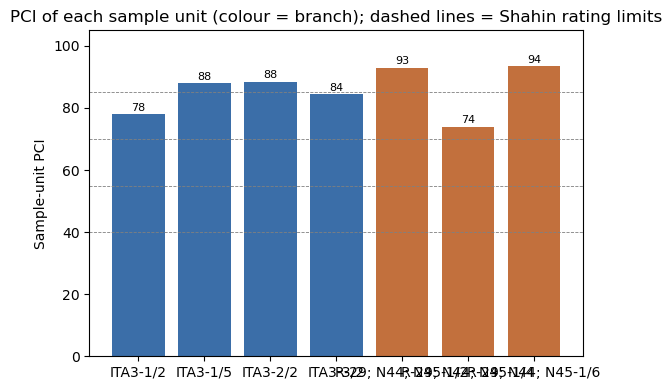

In [ ]:
fig, ax = plt.subplots(figsize=(max(6, 0.6 * len(sec_res)), 4))
palette = ['#3b6ea8', '#c2703d', '#4f9a6b', '#8a5aa8', '#b0a03c', '#5d8fa0']
bcol = {b: palette[i % len(palette)] for i, b in enumerate(sec_res.Branch.unique())}
ax.bar(sec_res.Sample, sec_res.PCI, color=sec_res.Branch.map(bcol))
for lo in (85, 70, 55, 40):
    ax.axhline(lo, color='grey', lw=0.6, ls='--')
for x, v in zip(sec_res.Sample, sec_res.PCI):
    ax.text(x, v + 1, f'{v:.0f}', ha='center', fontsize=8)
ax.set_ylim(0, 105); ax.set_ylabel('Sample-unit PCI')
ax.set_title('PCI of each sample unit (colour = branch); dashed lines = Shahin rating limits')
plt.tight_layout(); plt.show()

## 5. M&R plan (Homework 4)

### 5.1 PCI of the branch and its sections (Homework 4, Table "PCI of branch and sections")

In [ ]:
pci_rows = []
for b, gb in survey_t.groupby('Branch', sort=False):
    bpci = branch_res.loc[branch_res.Branch == b, 'PCI'].iloc[0]
    first_b = True
    for smp in samples.loc[samples.Branch == b, 'Sample']:
        g = survey_t[survey_t.Sample == smp]
        spci = sample_res.loc[sample_res.Sample == smp, 'PCI'].iloc[0]
        area = samples.loc[samples.Sample == smp, 'Sample_area_m2'].iloc[0]
        if g.empty:
            g = pd.DataFrame([dict(Distress='', Severity='', Quantity=np.nan, Density_pct=np.nan)])
        for k, (_, d) in enumerate(g.iterrows()):
            pci_rows.append({
                'Branch': b if first_b else '',
                'Section/ Sample': LABEL[smp] if k == 0 else '',
                'Sample Area': f'{area:g}' if k == 0 else '',
                'Distress Code': d.Distress,
                'Extent': '' if pd.isna(d.Quantity) else f'{d.Quantity:g}',
                'Severity': '' if d.Severity in ('N', '') else d.Severity,
                'Density calculation (%)': '' if pd.isna(d.Quantity) else f'{d.Quantity:g}/{area:g} x 100 = {d.Density_pct:.1f}',
                'Section PCI': f'{spci:g}' if k == 0 else '',
                'Branch PCI': f'{bpci:g}' if first_b else '',
            })
            first_b = False
pci_table = pd.DataFrame(pci_rows)
pci_table

,Branch,Section/ Sample,Sample Area,Distress Code,Extent,Severity,Density calculation (%),Section PCI,Branch PCI
0,ITA3,1/2,280,19,25,L,25/280 x 100 = 8.9,78,85
1,,,,2,2,L,2/280 x 100 = 0.7,,
2,,,,12,10,,10/280 x 100 = 3.6,,
3,,,,1,7,L,7/280 x 100 = 2.5,,
4,,1/5,280,19,20,L,20/280 x 100 = 7.1,88,
5,,,,12,25,,25/280 x 100 = 8.9,,
6,,,,11,10,L,10/280 x 100 = 3.6,,
7,,2/2,280,19,120,L,120/280 x 100 = 42.9,88.5,
8,,3/2,300,10,7,L,7/300 x 100 = 2.3,84.5,
9,,,,11,10.5,L,10.5/300 x 100 = 3.5,,


### 5.2 M&R type and quantity (Homework 4, Table "M&R Type & Quantity")

For each section (`MR_LEVEL`) and each distress type and severity, from the Survey sheet only:

* (1) total distress in the inspected sample units (m², m or count);
* (2) area of the samples inspected;
* density = (1)/(2) × 100, which selects the column of the decision matrix (< 10 %, 10–50 %, > 50 %);
* M&R type = number and description from the unit-cost file (1 = Do Nothing, 4 = Crack Sealing, …);
* **estimated section quantity to be treated = (1)/(2) × section area** (section area from the Areas sheet;
  nothing for Do Nothing). Without an Areas entry, the quantity in the sample units is shown instead.

In [ ]:
def qty_expr(series):
    vals = [f'{v:g}' for v in series]
    return f"({'+'.join(vals)}) = {sum(series):g}" if len(vals) > 1 else f'{sum(series):g}'

key = 'Branch' if MR_LEVEL == 'Branch' else 'Section'
st = survey_t.assign(Unit_ID=survey_t[key])
sm = samples.assign(Unit_ID=samples[key])
insp = sm.groupby('Unit_ID', sort=False).agg(Area_inspected_m2=('Sample_area_m2', 'sum'),
                                            Area_breakdown=('Sample_area_m2', qty_expr)).reset_index()
dis = (st.groupby(['Unit_ID', 'Branch', 'Distress', 'Severity'], as_index=False, sort=False)
         .agg(Total_distress=('Quantity', 'sum'), Distress_breakdown=('Quantity', qty_expr))
         .merge(insp, on='Unit_ID'))
dis['Distress_type'] = dis.Distress.map(lambda c: DISTRESS[c][0])
dis['Unit'] = dis.Distress.map(lambda c: DISTRESS[c][1])
dis['Density_pct'] = dis.Total_distress / dis.Area_inspected_m2 * 100
dis['Treatment'] = [select_treatment(c, s, d) for c, s, d in zip(dis.Distress, dis.Severity, dis.Density_pct)]

# a combined cell ("A & B") becomes two activities on the same quantity
mr = dis.assign(Description=dis.Treatment.str.split(' & ')).explode('Description')
mr['Description'] = mr.Description.str.strip()
mr['MR_type'] = mr.Description.map(MR_NO)
treat = mr.Description != 'Do Nothing'
mr['Quantity_in_samples'] = np.where(treat, mr.Total_distress, 0.0)
mr = mr.merge(mr_units[['Unit_ID', 'Section_area_m2']], on='Unit_ID', how='left')
mr['Section_quantity'] = np.where(treat, mr.Total_distress / mr.Area_inspected_m2 * mr.Section_area_m2, 0.0)
mr = mr.reset_index(drop=True)

def mr_table(uid):
    t = mr[mr.Unit_ID == uid]
    return pd.DataFrame({
        'Distress Code': t.Distress,
        'Distress Type': t.Distress_type.str.lower(),
        'Severity Level': t.Severity.replace('N', ''),
        'Total distress in sample units (1)': t.Distress_breakdown,
        'Area of samples inspected (m2) (2)': t.Area_breakdown,
        'Density [(1)/(2)]*100': [f'({q:g}/{a:g})*100 = {d:.2f}' for q, a, d in
                                  zip(t.Total_distress, t.Area_inspected_m2, t.Density_pct)],
        'M&R Type': t.MR_type,
        'Description': t.Description,
        'Section area (m2)': t.Section_area_m2.map(lambda v: '-' if np.isnan(v) else f'{v:g}'),
        'Estimated section quantity to be treated [(1)/(2)] x Section area': [
            '-' if d == 'Do Nothing' else
            f'({q:g}/{a:g}) x {sa:g} = {e:,.2f} {u}'
            for d, q, a, sa, e, u in zip(t.Description, t.Total_distress, t.Area_inspected_m2,
                                         t.Section_area_m2, t.Section_quantity, t.Unit)],
    }).reset_index(drop=True)

for uid in insp.Unit_ID:
    print(f'\nM&R Type & Quantity of {uid}')
    display(mr_table(uid))


M&R Type & Quantity of ITA3


,Distress Code,Distress Type,Severity Level,Total distress in sample units (1),Area of samples inspected (m2) (2),Density [(1)/(2)]*100,M&R Type,Description,Section area (m2),Estimated section quantity to be treated [(1)/(2)] x Section area
0,19,weathering & raveling,L,(25+20+120+6) = 171,(280+280+280+300) = 1140,(171/1140)*100 = 15.00,1,Do Nothing,11400,-
1,2,bleeding,L,(2+4) = 6,(280+280+280+300) = 1140,(6/1140)*100 = 0.53,1,Do Nothing,11400,-
2,12,polished aggregate,,(10+25+60) = 95,(280+280+280+300) = 1140,(95/1140)*100 = 8.33,1,Do Nothing,11400,-
3,1,alligator cracking,L,7,(280+280+280+300) = 1140,(7/1140)*100 = 0.61,1,Do Nothing,11400,-
4,11,patching & utility cut patching,L,(10+10.5) = 20.5,(280+280+280+300) = 1140,(20.5/1140)*100 = 1.80,1,Do Nothing,11400,-
5,10,longitudinal & transverse cracking,L,7,(280+280+280+300) = 1140,(7/1140)*100 = 0.61,4,Crack Sealing,11400,(7/1140) x 11400 = 70.00 m
6,9,lane/shoulder drop-off,L,30,(280+280+280+300) = 1140,(30/1140)*100 = 2.63,1,Do Nothing,11400,-



M&R Type & Quantity of R-29; N44; N45


,Distress Code,Distress Type,Severity Level,Total distress in sample units (1),Area of samples inspected (m2) (2),Density [(1)/(2)]*100,M&R Type,Description,Section area (m2),Estimated section quantity to be treated [(1)/(2)] x Section area
0,10,longitudinal & transverse cracking,L,(9+1) = 10,(245+245+245) = 735,(10/735)*100 = 1.36,4,Crack Sealing,7350,(10/735) x 7350 = 100.00 m
1,10,longitudinal & transverse cracking,M,3,(245+245+245) = 735,(3/735)*100 = 0.41,4,Crack Sealing,7350,(3/735) x 7350 = 30.00 m
2,19,weathering & raveling,L,7.5,(245+245+245) = 735,(7.5/735)*100 = 1.02,1,Do Nothing,7350,-
3,6,depression,L,0.6,(245+245+245) = 735,(0.6/735)*100 = 0.08,1,Do Nothing,7350,-
4,1,alligator cracking,L,10,(245+245+245) = 735,(10/735)*100 = 1.36,1,Do Nothing,7350,-
5,11,patching & utility cut patching,L,7,(245+245+245) = 735,(7/735)*100 = 0.95,1,Do Nothing,7350,-


### 5.3 Summary of the M&R plan

In [ ]:
summary_rows = []
for uid in insp.Unit_ID:
    t = mr[(mr.Unit_ID == uid) & (mr.Description != 'Do Nothing')]
    b = sm.loc[sm.Unit_ID == uid, 'Branch'].iloc[0]
    if t.empty:
        summary_rows.append({'Road Type': ROAD_TYPE, 'Branch Code': b, 'Section': uid, 'M&R Type': 'Do Nothing', 'Quantity': '-'})
        continue
    for desc, g in t.groupby('Description', sort=False):
        parts = [(f"{q:g} {u} (sample units)" if np.isnan(sa) else f"{e:,.2f} {u}") + f" for {n.lower()}"
                 + ('' if s == 'N' else f' ({s})')
                 for q, e, sa, u, n, s in zip(g.Total_distress, g.Section_quantity, g.Section_area_m2,
                                              g.Unit, g.Distress_type, g.Severity)]
        summary_rows.append({'Road Type': ROAD_TYPE, 'Branch Code': b, 'Section': uid, 'M&R Type': desc,
                             'Quantity': ', and '.join(parts)})
summary = pd.DataFrame(summary_rows)
if MR_LEVEL == 'Branch':
    summary = summary.drop(columns='Section')
summary

,Road Type,Branch Code,M&R Type,Quantity
0,Roads,ITA3,Crack Sealing,70.00 m for longitudinal & transverse cracking...
1,Roads,R-29; N44; N45,Crack Sealing,100.00 m for longitudinal & transverse crackin...


### 5.4 Maintenance quantity and cost

**Maintenance quantity = (total area of each distress in the section / area of samples inspected) × section area**;
**cost = unit cost (from the unit-cost Excel file) × maintenance quantity**.

In [ ]:
cost = mr[mr.Description != 'Do Nothing'].reset_index(drop=True)
cost['Maintenance_quantity'] = cost.Section_quantity
cost['Unit_cost_SAR'] = cost.Description.map(UNIT_COST)
cost['Cost_SAR'] = cost.Maintenance_quantity * cost.Unit_cost_SAR

cost_table = pd.DataFrame({
    'Section code': cost.Unit_ID,
    'Distress': [f"{c}{'' if s == 'N' else s} {n.lower()}" for c, s, n in zip(cost.Distress, cost.Severity, cost.Distress_type)],
    'M&R Type': cost.MR_type,
    'Description': cost.Description,
    'Maintenance quantity = (1)/(2) x Section area': [
        f'({q:g}/{a:g}) x {sa:g} = {m:,.2f} {u}'
        for q, a, sa, m, u in zip(cost.Total_distress, cost.Area_inspected_m2, cost.Section_area_m2,
                                  cost.Maintenance_quantity, cost.Unit)],
    'Unit cost (SAR)': cost.Unit_cost_SAR,
    'Cost (SAR)': cost.Cost_SAR.round(2),
})
display(cost_table)

,Section code,Distress,M&R Type,Description,Maintenance quantity = (1)/(2) x Section area,Unit cost (SAR),Cost (SAR)
0,ITA3,10L longitudinal & transverse cracking,4,Crack Sealing,(7/1140) x 11400 = 70.00 m,0.50,35.00
1,R-29; N44; N45,10L longitudinal & transverse cracking,4,Crack Sealing,(10/735) x 7350 = 100.00 m,0.50,50.00
2,R-29; N44; N45,10M longitudinal & transverse cracking,4,Crack Sealing,(3/735) x 7350 = 30.00 m,0.50,15.00


### 5.5 Total maintenance quantity and cost per section code and for all sections

Quantities are summed separately by unit (m², linear m, number), since different units cannot be added together.

In [ ]:
UNITS = [u for u in ('m2', 'm', 'no.') if u in set(cost.Unit)] or ['m2']

def totals_row(df, label, area):
    row = {'Section code': label, 'Section area (m2)': area}
    for u in UNITS:
        row[f'Maintenance quantity ({u})'] = df.loc[df.Unit == u, 'Maintenance_quantity'].sum()
    row['Cost (SAR)'] = df.Cost_SAR.sum()
    return row

areas = dict(zip(mr_units.Unit_ID, mr_units.Section_area_m2))
rows = [totals_row(cost[cost.Unit_ID == uid], uid, areas[uid]) for uid in insp.Unit_ID]
rows.append(totals_row(cost, 'Total (all sections)', sum(areas[u] for u in insp.Unit_ID)))
section_totals = pd.DataFrame(rows).round(2)

tot = section_totals.iloc[-1]
print('Total maintenance quantity of all sections: ' +
      ', '.join(f"{tot[f'Maintenance quantity ({u})']:,.2f} {u}" for u in UNITS))
print(f"Total cost of all sections: {tot['Cost (SAR)']:,.2f} SAR")
section_totals

Total maintenance quantity of all sections: 200.00 m
Total cost of all sections: 100.00 SAR


,Section code,Section area (m2),Maintenance quantity (m),Cost (SAR)
0,ITA3,"11,400.00",70.00,35.00
1,R-29; N44; N45,"7,350.00",130.00,65.00
2,Total (all sections),"18,750.00",200.00,100.00


In [ ]:
# Breakdown by M&R activity, per section code and for all sections
agg = dict(Maintenance_quantity=('Maintenance_quantity', 'sum'),
           Unit_cost_SAR=('Unit_cost_SAR', 'first'), Cost_SAR=('Cost_SAR', 'sum'))
by_activity = (cost.groupby(['Unit_ID', 'MR_type', 'Description', 'Unit'], as_index=False, sort=False).agg(**agg)
                   .rename(columns={'Unit_ID': 'Section code'}))
all_act = cost.groupby(['MR_type', 'Description', 'Unit'], as_index=False).agg(**agg)
all_act.insert(0, 'Section code', 'All sections')
by_activity = pd.concat([by_activity, all_act], ignore_index=True).round(2)
by_activity

,Section code,MR_type,Description,Unit,Maintenance_quantity,Unit_cost_SAR,Cost_SAR
0,ITA3,4,Crack Sealing,m,70.00,0.50,35.00
1,R-29; N44; N45,4,Crack Sealing,m,130.00,0.50,65.00
2,All sections,4,Crack Sealing,m,200.00,0.50,100.00


## 6. Export

In [ ]:
with pd.ExcelWriter('PCI_MR_results.xlsx') as xw:
    dv_table.to_excel(xw, sheet_name='HW3 Deduct values', index=False)
    iter_table.to_excel(xw, sheet_name='HW3 Iterations', index=False)
    branch_res.to_excel(xw, sheet_name='HW3 Branch PCI', index=False)
    pci_table.to_excel(xw, sheet_name='HW4 PCI of branch', index=False)
    for uid in insp.Unit_ID:
        mr_table(uid).to_excel(xw, sheet_name=f'M&R {uid}'.replace('/', '-')[:31], index=False)
    summary.to_excel(xw, sheet_name='HW4 Summary', index=False)
    mr_units.to_excel(xw, sheet_name='Section areas', index=False)
    unit_cost_table.to_excel(xw, sheet_name='Unit costs used', index=False)
    cost_table.to_excel(xw, sheet_name='Cost detail', index=False)
    section_totals.to_excel(xw, sheet_name='Totals by section', index=False)
    by_activity.to_excel(xw, sheet_name='Totals by activity', index=False)
    survey_t.to_excel(xw, sheet_name='Detail', index=False)
print('Saved PCI_MR_results.xlsx')

Saved PCI_MR_results.xlsx
